# 02 · Análisis exploratorio

Cada sección parte de una pregunta que se hace quien publica una librería en su primer mes. Las respuestas deciden cómo es el modelo y qué enseña la aplicación.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from radar import config, contraste, eda

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
VERDE, AZUL, ROJO, GRIS = "#1e7a52", "#2f5bd7", "#b3402a", "#8a8f98"

ds = pd.read_csv(
    config.DIR_PROCESADO / "dataset_radar.csv", parse_dates=["fecha_lanzamiento"]
)
diarias = pd.read_csv(config.DIR_PROCESADO / "descargas_diarias.csv")
print(
    f"{len(ds)} lanzamientos entre {ds.fecha_lanzamiento.min():%Y-%m-%d} y {ds.fecha_lanzamiento.max():%Y-%m-%d}"
)

5217 lanzamientos entre 2025-11-23 y 2026-10-09


## P1. ¿Cuánto de lo que cuenta PyPI es uso real?

0.10    0.022
0.25    0.033
0.50    0.051
0.75    0.091
0.90    0.258
dtype: float64

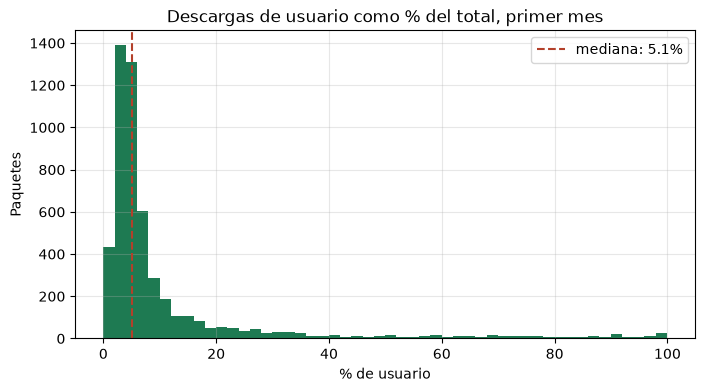

In [2]:
pct = eda.pct_usuario(ds)
fig, ax = plt.subplots()
ax.hist(pct * 100, bins=50, color=VERDE)
ax.axvline(
    pct.median() * 100, color=ROJO, ls="--", label=f"mediana: {pct.median():.1%}"
)
ax.set(
    title="Descargas de usuario como % del total, primer mes",
    xlabel="% de usuario",
    ylabel="Paquetes",
)
ax.legend()
pct.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(3)

In [3]:
# ¿Cambia con el tamaño? Cuartiles de descargas de usuario a 30 días
cuartil = pd.qcut(
    ds["usuario_30d"].rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"]
)
ds.assign(pct_usuario=pct).groupby(cuartil, observed=True).agg(
    usuario_30d=("usuario_30d", "median"),
    total_30d=("total_30d", "median"),
    pct_usuario=("pct_usuario", "median"),
).round(3)

,usuario_30d,total_30d,pct_usuario
usuario_30d,,,
Q1,20.0,499.0,0.032
Q2,58.0,1185.5,0.048
Q3,152.0,2583.5,0.057
Q4,684.0,6579.0,0.150


**Conclusión.** En el paquete mediano, solo el 5 % de las descargas de su primer mes vienen de alguien que lo instala con pip, uv o poetry; una de cada diez no llega al 2 %. El resto son mirrors que copian cada fichero nuevo, escáneres de seguridad y bots. El contador que enseña PyPI (y las webs que lo copian) no sirve para saber si un lanzamiento ha llegado a alguien: un paquete sin ningún usuario real ronda las 500 descargas. Solo en el cuartil más grande el uso real pesa algo más (15 %). **El radar trabaja con las descargas de usuario.**

## P2. ¿Publicar versiones infla las descargas?

ρ con las subidas — totales:

 0.83 · de usuario: 0.64
Descargas automáticas por día con subida (mediana): 517


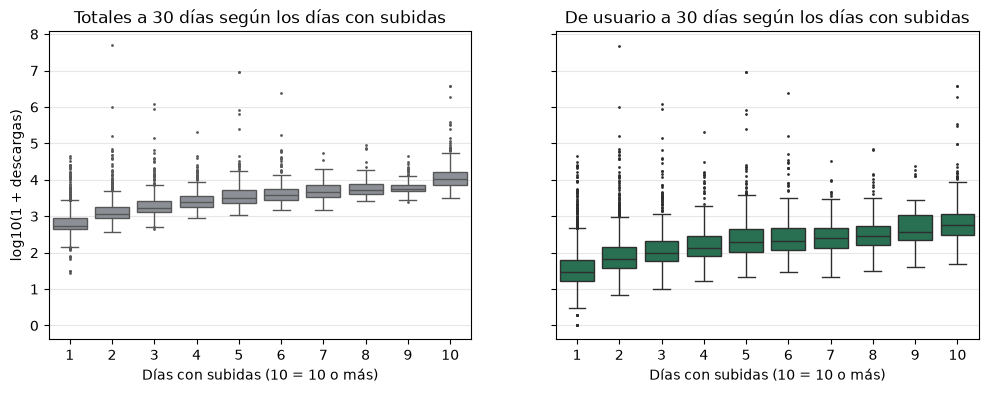

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
grupos = ds["subidas_30d"].clip(upper=10)
for ax, col, color, titulo in [
    (axes[0], "total_30d", GRIS, "Totales"),
    (axes[1], "usuario_30d", VERDE, "De usuario"),
]:
    sns.boxplot(x=grupos, y=np.log10(ds[col] + 1), ax=ax, color=color, fliersize=1)
    ax.set(
        title=f"{titulo} a 30 días según los días con subidas",
        xlabel="Días con subidas (10 = 10 o más)",
        ylabel="log10(1 + descargas)",
    )
print(
    "ρ con las subidas — totales:",
    round(eda.spearman(ds, "total_30d", "subidas_30d"), 2),
    "· de usuario:",
    round(eda.spearman(ds, "usuario_30d", "subidas_30d"), 2),
)
print(
    "Descargas automáticas por día con subida (mediana):",
    round(eda.descargas_por_subida(ds)),
)

**Conclusión.** Sí, y mucho. Cada día con un fichero nuevo trae unas 520 descargas automáticas, lo use alguien o no; por eso las totales siguen al número de subidas (ρ = 0,83) casi tanto como a cualquier otra cosa. Las de usuario también suben con las subidas (ρ = 0,64), pero ahí hay una parte real: los proyectos activos publican más y se usan más. Para el modelo, las subidas hasta el día de lectura entran como variable, para que pueda descontar lo que queda de ese efecto.

## P3. ¿Qué parte de las descargas del primer mes llega en los primeros días?

dia
día 7     0.500
día 14    0.709
día 21    0.862
dtype: float64

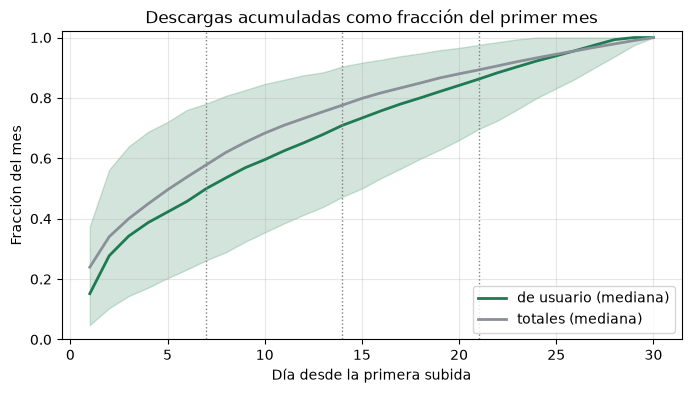

In [5]:
ventana = diarias[diarias["dia"].between(0, 29)]
fig, ax = plt.subplots()
dias = np.arange(1, 31)
for col, color, etiqueta in [
    ("usuario", VERDE, "de usuario"),
    ("total", GRIS, "totales"),
]:
    tabla = ventana.pivot_table(
        index="paquete", columns="dia", values=col, aggfunc="sum"
    )
    tabla = tabla.reindex(columns=range(30), fill_value=0).fillna(0)
    fraccion = tabla.cumsum(axis=1).div(tabla.sum(axis=1).replace(0, np.nan), axis=0)
    if col == "usuario":
        ax.fill_between(
            dias,
            fraccion.quantile(0.25),
            fraccion.quantile(0.75),
            color=color,
            alpha=0.2,
        )
        mediana_usuario = fraccion.median()
    ax.plot(dias, fraccion.median(), color=color, lw=2, label=f"{etiqueta} (mediana)")
for d in config.DIAS_LECTURA:
    ax.axvline(d, color="grey", ls=":", lw=1)
ax.set(
    title="Descargas acumuladas como fracción del primer mes",
    xlabel="Día desde la primera subida",
    ylabel="Fracción del mes",
    ylim=(0, 1.02),
)
ax.legend(loc="lower right")
mediana_usuario[[d - 1 for d in config.DIAS_LECTURA]].rename(
    lambda d: f"día {d + 1}"
).round(3)

**Conclusión.** Las descargas de usuario llegan algo más repartidas que las totales, que saltan el día de la subida: en el paquete mediano, el día 7 ya ha llegado la mitad de las del mes, el día 14 el 71 % y el día 21 el 86 %. Es más lento que en otros mercados (en Steam, el 62 % de las reseñas llega en la primera semana), así que la primera lectura útil es el día 7, no el 3: los tres primeros días son casi solo ruido de la subida.

## P4. ¿Las descargas de la primera semana anticipan las del mes?

7     2.00
14    1.41
21    1.16
Name: multiplicador mediano hasta el día 30, dtype: float64

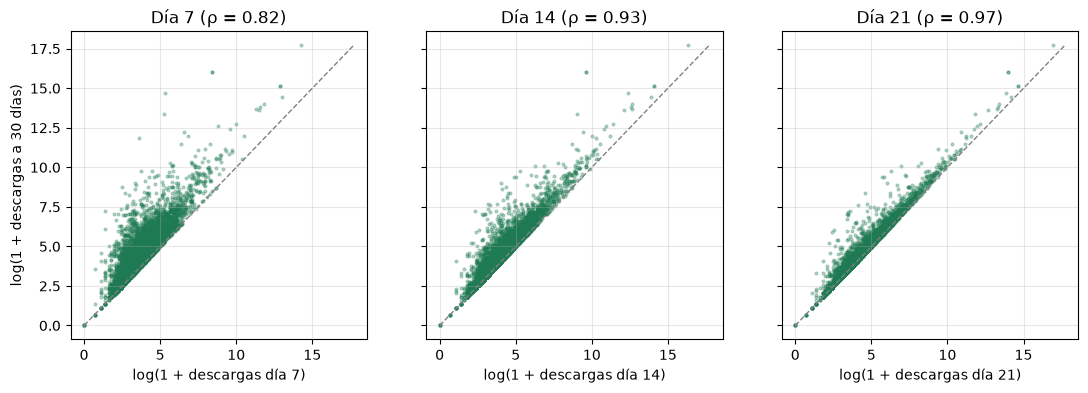

In [6]:
fig, axes = plt.subplots(1, len(config.DIAS_LECTURA), figsize=(13, 4), sharey=True)
for ax, d in zip(axes, config.DIAS_LECTURA, strict=True):
    ax.scatter(
        np.log1p(ds[f"usuario_{d}d"]),
        np.log1p(ds["usuario_30d"]),
        s=4,
        alpha=0.3,
        color=VERDE,
    )
    lim = np.log1p(ds["usuario_30d"].max())
    ax.plot([0, lim], [0, lim], color="grey", lw=1, ls="--")
    rho = eda.spearman(ds, f"usuario_{d}d", "usuario_30d")
    ax.set(title=f"Día {d} (ρ = {rho:.2f})", xlabel=f"log(1 + descargas día {d})")
axes[0].set_ylabel("log(1 + descargas a 30 días)")
multiplicador = {
    d: (ds["usuario_30d"] / ds[f"usuario_{d}d"].replace(0, np.nan)).median()
    for d in config.DIAS_LECTURA
}
pd.Series(multiplicador, name="multiplicador mediano hasta el día 30").round(2)

**Conclusión.** En escala logarítmica la relación es casi una recta, más dispersa al principio (ρ de 0,82 el día 7, 0,93 el día 14 y 0,97 el día 21). El multiplicador mediano hasta el mes es ×2 desde el día 7, ×1,4 desde el 14 y ×1,16 desde el 21. Con esa regla de hoja de cálculo («descargas de hoy × multiplicador típico») ya se tiene un baseline difícil de batir; el modelo tiene que mejorarla para justificar su complejidad.

## P5. Antes de lanzar, ¿la categoría o quién publica dicen cuánto se usará?

ε² de Kruskal-Wallis: {'categoria': 0.005, 'propietario': 0.004}
ρ con dependencias: 0.085
ρ con anios_cuenta: -0.01
ρ con dias_repo_previos: -0.094


categoria
Agentes y LLM                 2735
Datos y ciencia                629
Machine learning               588
Herramientas de desarrollo     469
Otras                          376
Web y APIs                     337
Sistema y automatización        83
Name: count, dtype: int64

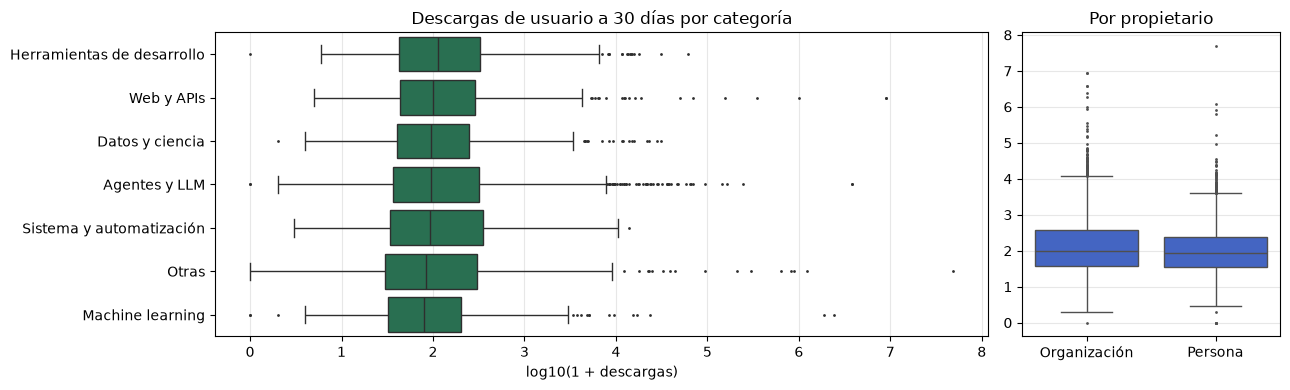

In [7]:
orden = (
    ds.groupby("categoria")["usuario_30d"].median().sort_values(ascending=False).index
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
sns.boxplot(
    data=ds,
    y="categoria",
    x=np.log10(ds["usuario_30d"] + 1),
    order=orden,
    ax=axes[0],
    color=VERDE,
    fliersize=1,
)
axes[0].set(
    title="Descargas de usuario a 30 días por categoría",
    xlabel="log10(1 + descargas)",
    ylabel="",
)
sns.boxplot(
    data=ds,
    x="propietario_tipo",
    y=np.log10(ds["usuario_30d"] + 1),
    ax=axes[1],
    color=AZUL,
    fliersize=1,
)
axes[1].set(title="Por propietario", xlabel="", ylabel="")
plt.tight_layout()
print("ε² de Kruskal-Wallis:", eda.efecto_grupos(ds))
for col in ["dependencias", "anios_cuenta", "dias_repo_previos"]:
    print(
        f"ρ con {col}:",
        round(
            stats.spearmanr(ds[col], ds["usuario_30d"], nan_policy="omit").statistic, 3
        ),
    )
ds["categoria"].value_counts()

**Conclusión.** Casi nada. La categoría explica el 0,5 % de la variación de rangos (ε²) y el tipo de propietario el 0,4 %: el paquete mediano de una organización tiene 100 descargas de usuario en su primer mes y el de una persona, 88. Las dependencias, la antigüedad de la cuenta o del repositorio tampoco ordenan (|ρ| ≤ 0,1). Antes de publicar se puede situar un rango, no dar una cifra. Además, la mitad de la muestra es «Agentes y LLM»: en 2026, la mayoría de las librerías nuevas que consiguen algo de atención van de agentes o de MCP.

## P6. ¿Las estrellas de GitHub dicen lo mismo que las descargas?

Repositorios: 3748 · ρ de Spearman: 0.2
Descargas de usuario por estrella: {'mediana': 3.25, 'q25': 1.22, 'q75': 9.05}


,paquete,repo,estrellas,usuario_30d
0,strix-sandbox,usestrix/strix,77208,3
1,clovyr-workspace-mcp,taylorwilsdon/google_workspace_mcp,3569,13
2,openworker,andrewyng/openworker,19552,26
3,athena-agent,winstonkoh87/athena-public,650,9
4,plasma-fractal,plasma-ai/fractal,798,11


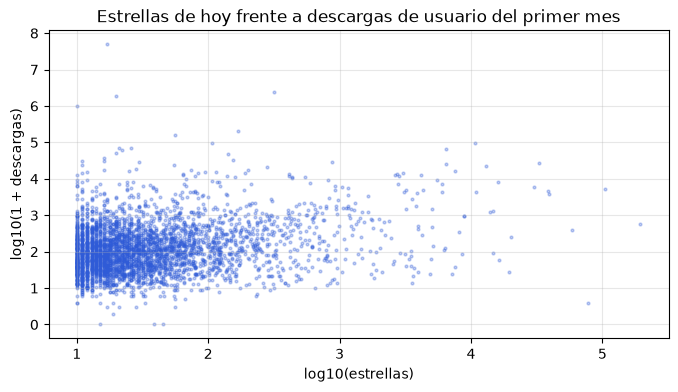

In [8]:
unicos = contraste.un_paquete_por_repo(ds)
fig, ax = plt.subplots()
ax.scatter(
    np.log10(unicos["estrellas"]),
    np.log10(unicos["usuario_30d"] + 1),
    s=4,
    alpha=0.3,
    color=AZUL,
)
ax.set(
    title="Estrellas de hoy frente a descargas de usuario del primer mes",
    xlabel="log10(estrellas)",
    ylabel="log10(1 + descargas)",
)
resumen = contraste.resumen(ds)
print("Repositorios:", resumen["repos"], "· ρ de Spearman:", resumen["spearman"])
print("Descargas de usuario por estrella:", resumen["descargas_por_estrella"])
pd.DataFrame(resumen["mas_estrellas_que_uso"])

In [9]:
pd.DataFrame(resumen["mas_uso_que_estrellas"])

,paquete,repo,estrellas,usuario_30d
0,uncalled-for,chrisguidry/uncalled-for,17,48753650
1,ultralytics-platform,ultralytics/sdk,20,1876226
2,cross-web,usecross/cross-web,10,1006208
3,typesafe-sdk,typesafe-ai/typesafe-sdk-python,316,2435606
4,wecom-aibot-python-sdk,wecomteam/wecom-aibot-python-sdk,56,156743


**Conclusión.** Muy poco. Entre 3.748 repositorios (un paquete por repositorio), la correlación de rangos entre estrellas y descargas de usuario del primer mes es de 0,20. Miden cosas distintas: las estrellas, atención (aplicaciones y demos con decenas de miles de estrellas que casi nadie instala desde PyPI); las descargas, uso (dependencias que otro paquete arrastra, con millones de instalaciones y 10 o 20 estrellas). Un proyecto que solo mire sus estrellas no sabe si alguien lo usa, y al revés. El radar predice descargas de usuario; las estrellas quedan como contexto.

## P7. ¿Es representativa la muestra?

,paquetes,mediana_usuario_30d,mediana_estrellas
fecha_lanzamiento,,,
2025Q4,635,58.0,27.0
2026Q1,1931,77.0,30.0
2026Q2,1599,132.0,27.0
2026Q3,957,112.0,24.0
2026Q4,95,90.0,24.0


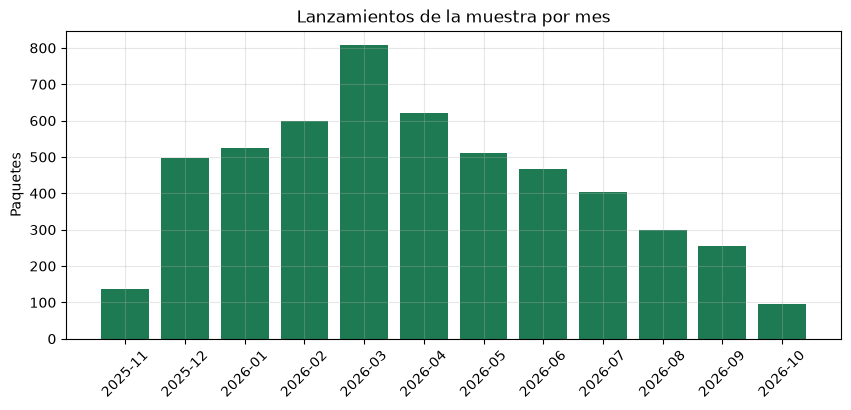

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
por_mes = ds.groupby(ds["fecha_lanzamiento"].dt.to_period("M")).agg(
    paquetes=("paquete", "size"), mediana_30d=("usuario_30d", "median")
)
ax.bar(por_mes.index.astype(str), por_mes["paquetes"], color=VERDE)
ax.set(title="Lanzamientos de la muestra por mes", ylabel="Paquetes")
ax.tick_params(axis="x", rotation=45)
ds.groupby(ds["fecha_lanzamiento"].dt.to_period("Q")).agg(
    paquetes=("paquete", "size"),
    mediana_usuario_30d=("usuario_30d", "median"),
    mediana_estrellas=("estrellas", "median"),
)

**Conclusión.** No del todo. La muestra exige 10 estrellas el día de la descarga, y un proyecto publicado hace tres meses ha tenido menos tiempo de conseguirlas que uno de hace diez: los últimos meses tienen menos lanzamientos (de 807 en marzo a 254 en septiembre). La mediana de descargas de usuario a 30 días se mueve entre trimestres (de 58 a 132) sin una tendencia clara. Como la partición es temporal, el test es el periodo más reciente: si el sesgo afecta, se ve en el test y no queda escondido.

## Qué implica para el modelo y la aplicación

1. **Objetivo: descargas de usuario**, no totales: el total es sobre todo ruido (P1, P2).
2. **Objetivo en log(1 + descargas)** por la asimetría (01, apartado 7).
3. **Lecturas a 7, 14 y 21 días**: los tres primeros días son ruido de la subida y el día 7 ya llega la mitad del mes (P3).
4. **Baseline exigente**: la regla del multiplicador típico, porque la relación es casi lineal en log (P4).
5. **Subidas y descargas totales como variables**, para descontar el efecto de publicar versiones (P2).
6. **Antes de lanzar, un rango y no una cifra** (P5).
7. **Las estrellas, como contraste y no como objetivo** (P6).
8. **Partición temporal**, para que el test sea lo más reciente y el sesgo de selección no quede escondido (P7).